# 15 — Fixing the deployed interval near failure

**Why this notebook exists.** Notebook 14 found that the deployed 90% interval (Weibull AFT) covers only 58% (FD001) and 54% (FD004) of test engines within 25 cycles of failure. Every one of those misses promises *more* life than the engine has: the dangerous direction. The calibrated RSF interval covers all of them, but fails above the 125-cycle cap, where Weibull holds up. This notebook selects a replacement on training data, then confirms it on the test sets.

**Why notebook 12 missed it.** Its calibration scored each held-out training engine once, at a random point between 30% and 90% of its life, so almost no calibration point was close to failure. Here each engine is scored at **10 random points between 30% and 99% of its life**, by fold models that never saw it (`interval_calibration.out_of_fold_intervals`, 5 folds, the deployed RSF and Weibull recipes).

**Candidates** (`interval_calibration.candidates()`; see that module for definitions):

| Candidate | Lower bound | Upper bound | Correction |
|---|---|---|---|
| `weibull+none` | Weibull | Weibull | none (the old deployment) |
| `rsf+global` | RSF | RSF | one conformal *q* (the Phase 14 method) |
| `weibull+mondrian` | Weibull | Weibull | one *q* per band of the RSF prediction |
| `hybrid+none` | min(RSF, Weibull) | Weibull | none |
| `hybrid+global` | min(RSF, Weibull) | Weibull | one *q* |
| `hybrid+mondrian` | min(RSF, Weibull) | Weibull | one *q* per prediction band |

**How candidates are scored.** Out-of-fold rows only, with the corrections cross-fitted: calibrate on half of the engines, evaluate on the other half, then swap. A candidate is never scored on the rows its own correction was fitted on.

**Selection rule.** Eligible if, on **both** FD001 and FD004, out-of-fold coverage is ≥ 88% overall **and** ≥ 85% for engines within 25 cycles of failure. Among eligible candidates, the narrowest wins (mean width averaged over the two subsets). Above-cap coverage is reported but not used: every Weibull-based candidate shares Weibull's upper bound, so it can't separate them, and misses there promise *too little* life (costly, not dangerous).

**Confirmation rule (official test sets, once).** The selected interval replaces Weibull only if, on both subsets, test coverage is ≥ 85% overall and ≥ 85% within 25 cycles of failure.

**Disclosure.** The selection rule was finalised after a first look at FD001's out-of-fold table showed that above-cap coverage is identical across the Weibull-based candidates. The test sets were not consulted for that. They *were* used by notebook 14 to find the problem, so the confirmation step is not a fully independent test. The out-of-fold results are the main evidence; the test sets confirm them.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path("..") / "src"))
from turbofan_rul import data_loading, inference, interval_calibration as ic, plotting
from turbofan_rul import export_deployment_artifacts as export

plotting.style()
SUBSETS = ["FD001", "FD004"]
DATA_DIR = Path("..") / "data" / "raw"
PROCESSED_DIR = Path("..") / "data" / "processed"
MODELS_DIR = Path("..") / "models"
TRUE_BANDS, TRUE_LABELS = [0, 25, 125, np.inf], ["true <= 25", "true 26-125", "true > 125"]
RECOMPUTE = False   # True re-fits the fold models (~6 minutes per subset)

## 1. Out-of-fold intervals on the training engines

In [2]:
oof = {}
for subset in SUBSETS:
    path = PROCESSED_DIR / f"interval_oof_{subset.lower()}.csv"
    if path.exists() and not RECOMPUTE:
        oof[subset] = pd.read_csv(path)
    else:
        t0 = time.time()
        data_loading.download_cmapss(subset, data_dir=DATA_DIR)
        cmapss = data_loading.load_subset(subset, data_dir=DATA_DIR)
        if subset in export.REGIME_CLUSTERED_SUBSETS:
            kept, train_for_labeling, _, _ = export._prepare_regime_clustered(subset, cmapss)
        else:
            kept, train_for_labeling, _, _ = export._prepare_fd001_style(subset, cmapss, PROCESSED_DIR)
        oof[subset] = ic.out_of_fold_intervals(
            train_for_labeling, kept,
            min_samples_leaf=export.RSF_MIN_SAMPLES_LEAF_BY_SUBSET[subset],
            row_stride=export.ROW_STRIDE_BY_SUBSET[subset],
        )
        oof[subset].to_csv(path, index=False)
        print(f"{subset}: computed in {time.time() - t0:.0f}s")
    f = oof[subset]
    print(f"{subset}: {len(f)} scored points from {f.unit_number.nunique()} engines; "
          f"by true RUL {pd.cut(f.true_rul, TRUE_BANDS, labels=TRUE_LABELS).value_counts().to_dict()}")

FD001: computed in 353s
FD001: 956 scored points from 100 engines; by true RUL {'true 26-125': 665, 'true <= 25': 165, 'true > 125': 126}


FD004: computed in 507s
FD004: 2417 scored points from 249 engines; by true RUL {'true 26-125': 1532, 'true > 125': 563, 'true <= 25': 322}


## 2. Compare the candidates (cross-fitted, training data only)

In [3]:
def cross_fitted(frame, base, mode):
    units = np.sort(frame.unit_number.unique())
    half = frame.unit_number.isin(units[::2])
    parts = []
    for cal_mask in (half, ~half):
        cal = ic.calibrate(frame[cal_mask], base, mode)
        ev = frame[~cal_mask].copy()
        ev["low"], ev["high"] = cal.apply(ev.rsf_pred, ev.rsf_low, ev.rsf_high, ev.weibull_low, ev.weibull_high)
        parts.append(ev)
    ev = pd.concat(parts)
    covered = ev.true_rul.between(ev.low, ev.high)
    band = pd.cut(ev.true_rul, TRUE_BANDS, labels=TRUE_LABELS)
    out = {"coverage": covered.mean(), "width": (ev.high - ev.low).mean()}
    out.update({b: covered[band == b].mean() for b in TRUE_LABELS})
    out["dangerous misses"] = (ev.true_rul < ev.low).mean()
    return out

rows = [{"subset": s, "candidate": f"{b}+{m}", **cross_fitted(oof[s], b, m)}
        for s in SUBSETS for b, m in ic.candidates()]
table = pd.DataFrame(rows).set_index(["candidate", "subset"]).unstack("subset")
table.round(3)

coverage           width          true <= 25         \
subset              FD001  FD004    FD001    FD004      FD001  FD004   
candidate                                                              
hybrid+global       0.936  0.905   95.483  108.421      1.000  0.994   
hybrid+mondrian     0.935  0.917   99.593  116.955      1.000  0.988   
hybrid+none         0.932  0.895   91.892  101.819      0.994  0.988   
rsf+global          0.889  0.896   68.140  127.632      1.000  1.000   
weibull+mondrian    0.919  0.904  101.876  118.483      0.903  0.891   
weibull+none        0.867  0.845   91.051  100.889      0.624  0.618   

                 true 26-125        true > 125        dangerous misses         
subset                 FD001  FD004      FD001  FD004            FD001  FD004  
candidate                                                                      
hybrid+global          0.974  0.977      0.651  0.659            0.000  0.002  
hybrid+mondrian        0.973  0.977      0.651  0.714            0.000  0.002  
hybrid+none            0.970  0.974      0.651  0.627            0.001  0.002  
rsf+global             0.983  1.000      0.246  0.552            0.007  0.000  
weibull+mondrian       0.974  0.977      0.651  0.714            0.017  0.016  
weibull+none           0.968  0.973      0.651  0.627            0.066  0.052

In [4]:
eligible = {
    cand: all(table.loc[cand, ("coverage", s)] >= 0.88 and table.loc[cand, ("true <= 25", s)] >= 0.85
              for s in SUBSETS)
    for cand in table.index
}
mean_width = table["width"].mean(axis=1)
summary = pd.DataFrame({"eligible": eligible, "mean width": mean_width.round(1)}).sort_values("mean width")
display(summary)
selected = summary[summary.eligible].index[0]
print(f"Selected by the rule: {selected}")

,eligible,mean width
weibull+none,False,96.0
hybrid+none,True,96.9
rsf+global,True,97.9
hybrid+global,True,102.0
hybrid+mondrian,True,108.3
weibull+mondrian,True,110.2


Selected by the rule: hybrid+none


**Reading the table.** The old interval (`weibull+none`) reproduces notebook 14's problem on training data alone: about 62% coverage within 25 cycles of failure on both subsets. Taking the more cautious lower bound (`hybrid+none`) lifts that to about 99% at almost no cost in width (+1 cycle on average), with no correction to fit. `rsf+global` is also eligible and only about a cycle wider on average, but it is the worst candidate above the cap. Mondrian corrections help above the cap on FD004 but cost 10–20 cycles of width.

Because the selected interval has no fitted correction, there is nothing to calibrate on the full out-of-fold set. The exported metadata records it (`"interval": {"base": "hybrid", "mode": "none", ...}`), and `inference.py` serves it by default for bundles exported before this change.

## 3. Confirm on the official test sets, through `inference.predict`

In [5]:
base, mode = selected.split("+")
assert (base, mode) == (inference.DEFAULT_INTERVAL.base, inference.DEFAULT_INTERVAL.mode), \
    "inference.py serves a different interval from the one selected here"

rows = []
for subset in SUBSETS:
    bundle = inference.load_deployment_bundle(MODELS_DIR / subset.lower())
    cmapss = data_loading.load_subset(subset, data_dir=DATA_DIR)
    true_rul = cmapss.rul.set_index("unit_number")["RUL"]
    for unit, engine in cmapss.test.groupby("unit_number"):
        engine = engine.sort_values("time_cycles")
        r = inference.predict(bundle, engine[["time_cycles"] + bundle.raw_passthrough_cols])
        rows.append(dict(subset=subset, unit=unit, true_rul=true_rul.loc[unit],
                         new_low=r["confidence_interval_90"][0], new_high=r["confidence_interval_90"][1],
                         old_low=r["weibull_interval_90"][0], old_high=r["weibull_interval_90"][1]))
test = pd.DataFrame(rows)
test["band"] = pd.cut(test.true_rul, TRUE_BANDS, labels=TRUE_LABELS)
for k in ["old", "new"]:
    test[f"{k}_covered"] = test.true_rul.between(test[f"{k}_low"], test[f"{k}_high"])
    test[f"{k}_width"] = test[f"{k}_high"] - test[f"{k}_low"]
    test[f"{k}_dangerous"] = test.true_rul < test[f"{k}_low"]
test.to_csv(PROCESSED_DIR / "interval_fix_test_check.csv", index=False)

def confirm(g):
    out = {}
    for k, label in [("old", "Weibull (old)"), ("new", "hybrid (new)")]:
        out[(label, "coverage")] = g[f"{k}_covered"].mean()
        out[(label, "width")] = g[f"{k}_width"].mean()
        for b in TRUE_LABELS:
            out[(label, b)] = g.loc[g.band == b, f"{k}_covered"].mean()
        out[(label, "dangerous misses")] = int(g[f"{k}_dangerous"].sum())
    return pd.Series(out)

confirmation = test.groupby("subset").apply(confirm, include_groups=False).T
display(confirmation.round(3))
passed = all(confirmation.loc[("hybrid (new)", "coverage"), s] >= 0.85
             and confirmation.loc[("hybrid (new)", "true <= 25"), s] >= 0.85 for s in SUBSETS)
print("Confirmation rule:", "PASSED -- the hybrid interval is deployed" if passed else "FAILED -- keep Weibull")

subset                           FD001    FD004
Weibull (old) coverage           0.890    0.806
              width             98.555   98.801
              true <= 25         0.579    0.540
              true 26-125        0.971    0.947
              true > 125         0.909    0.731
              dangerous misses   8.000   23.000
hybrid (new)  coverage           0.970    0.887
              width             99.680  100.049
              true <= 25         1.000    0.940
              true 26-125        0.971    0.947
              true > 125         0.909    0.731
              dangerous misses   0.000    3.000

Confirmation rule: PASSED -- the hybrid interval is deployed


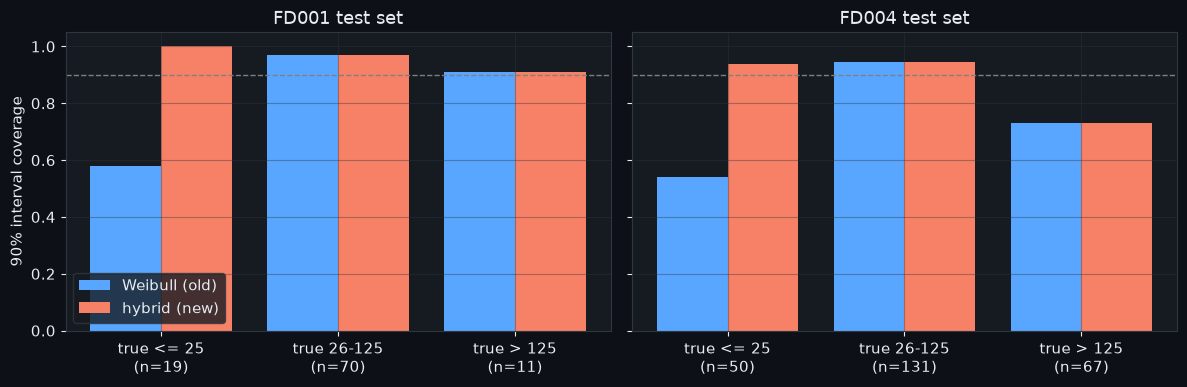

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, subset in zip(axes, SUBSETS):
    g = test[test.subset == subset]
    old = g.groupby("band", observed=True).old_covered.mean()
    new = g.groupby("band", observed=True).new_covered.mean()
    n = g.groupby("band", observed=True).size()
    x = np.arange(len(old))
    ax.bar(x - 0.2, old, 0.4, label="Weibull (old)")
    ax.bar(x + 0.2, new, 0.4, label="hybrid (new)")
    ax.axhline(0.9, color="grey", ls="--", lw=1)
    ax.set_xticks(x, [f"{b}\n(n={k})" for b, k in zip(old.index, n)])
    ax.set_title(f"{subset} test set")
axes[0].set_ylabel("90% interval coverage"); axes[0].legend(loc="lower left")
plt.tight_layout(); plt.show()

## 4. Findings and decision

**Selected and confirmed: `hybrid+none`.** The served interval's lower bound is now the more cautious of RSF's and Weibull's lower bounds; its upper bound stays Weibull's.

- **Within 25 cycles of failure:** test coverage rises from 58% to 100% on FD001 and from 54% to 94% on FD004. Dangerous misses (interval promising more life than the engine had) fall from 8 to 0 on FD001 and from 23 to 3 on FD004.
- **Overall:** 89.0% → 97.0% on FD001 and 80.6% → 88.7% on FD004, for about one extra cycle of average width.
- **Unchanged:** coverage between 26 and 125 cycles, and above the cap (FD001 91%, FD004 73%), because the upper bound is the same.

**What remains.** FD004's coverage above the cap (73%) is still short of 90%. Those misses are on the safe side: the engine outlives the interval. Every candidate here kept Weibull's upper bound, so fixing that needs a different model of long remaining life (for example, training without the 125-cycle cap). It isn't a calibration problem. Notebook 16 measures exactly that: an upper bound from an RSF trained without the cap reaches 100% above the cap on both test sets. It is recorded there rather than deployed, and that notebook explains why. FD001 overshoots the 90% target (97%), so its interval is conservative rather than tight.

**Deployment.** `inference.predict` serves the hybrid interval as `confidence_interval_90` and returns Weibull's own interval as `weibull_interval_90` for comparison. No model was retrained: the interval is computed from the RSF and Weibull models already exported, and bundles exported before this change serve it by default.